# 02_02 Lognormal

**Learning objectives**
- Understand why **multiplicative** effects produce a skewed, always-positive, long-tailed distribution (the Lognormal).
- Derive the PDF by change of variables, and the mean, variance, median and mode, and see why mean > median > mode.
- Convert between the Normal world (logs) and the Lognormal world (original values), and read `scipy`'s parametrization correctly.
- Solve three real problems (API latency, household income, investment growth) and fit real restaurant-bill data.

**Prerequisites:** [02_01 Uniform and Normal](02_01_uniform_normal.ipynb) (the Normal distribution, z-scores, Q-Q plot).

## 1. Setup

All imports live in one cell; the generator is seeded. The real dataset `tips.csv` is read from `../data/` (run `../data/download_data.py` if it is missing).

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Normal($\mu,\sigma^2$):** the bell curve; $z=(x-\mu)/\sigma$; its CDF is $\Phi$.
- **Logarithm rules:** $\ln(ab)=\ln a+\ln b$ and $\ln(a^k)=k\ln a$. So logs turn **products into sums**.
- **Change of variables:** if $Y=g(X)$ with $g$ increasing, then $F_Y(y)=F_X(g^{-1}(y))$ and $f_Y(y)=f_X(g^{-1}(y))\,\big|\tfrac{d}{dy}g^{-1}(y)\big|$.
- **Central Limit Theorem:** a *sum* of many small independent effects is approximately Normal.
- **Median** is the 50th percentile; **mode** is the peak of the density.

## 3. Intuition and story

### 3.1 Sums give Normals, products give Lognormals
Why are heights roughly Normal? Because height is the *sum* of many small additive effects (genes, nutrition, ...). Many other quantities are built by **multiplication**: a salary grows by 3 % one year and 5 % the next; the latency of a request is multiplied by factors for network, cache miss, database load; the size of a city is multiplied by yearly growth rates.

If $X=F_1F_2\cdots F_n$ is a product of many independent positive factors, then $\ln X=\ln F_1+\dots+\ln F_n$ is a **sum**, so by the Central Limit Theorem $\ln X$ is approximately Normal. A variable whose **logarithm is Normal** is called **Lognormal**.

Consequences you can already predict:
- $X>0$ always (an exponential is positive).
- The distribution is **right-skewed**: multiplying by 2 a few times in a row gives huge values, but values cannot go below zero.
- The **mean is larger than the median**, pulled up by the long right tail.

The next cell shows this with a simulation: each value is the product of 25 random growth factors between 0.8 and 1.3.

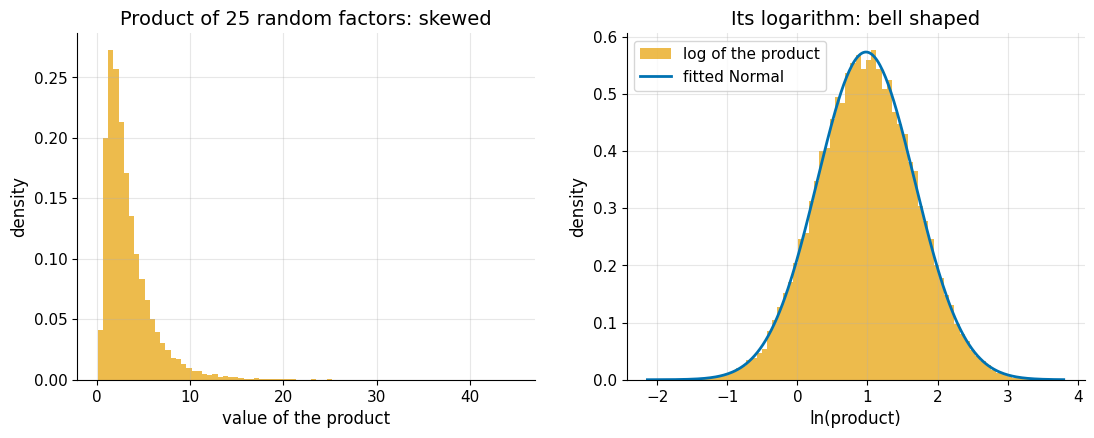

In [2]:
n_factors = 25
factors = rng.uniform(0.8, 1.3, size=(50_000, n_factors))      # each row: 25 random multipliers
products = factors.prod(axis=1)
log_products = np.log(products)

fig, (ax_raw, ax_log) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_raw.hist(products, bins=80, density=True, color=SIM, alpha=0.7)
ax_raw.set_title("Product of 25 random factors: skewed")
ax_raw.set_xlabel("value of the product")
ax_raw.set_ylabel("density")

grid = np.linspace(log_products.min(), log_products.max(), 300)
ax_log.hist(log_products, bins=80, density=True, color=SIM, alpha=0.7, label="log of the product")
ax_log.plot(grid, stats.norm(log_products.mean(), log_products.std()).pdf(grid), color=MAIN, linewidth=2, label="fitted Normal")
ax_log.set_title("Its logarithm: bell shaped")
ax_log.set_xlabel("ln(product)")
ax_log.set_ylabel("density")
ax_log.legend()
plt.show()

**In plain words.** Take logs and the multiplicative world becomes the additive world. A Lognormal is simply "a number whose log is Normal". Everything we know about the Normal carries over once we work on the log scale.

## 4. Formal definition

$X\sim\text{Lognormal}(\mu,\sigma^2)$ means $Y=\ln X\sim N(\mu,\sigma^2)$. Here $\mu$ and $\sigma$ are the **mean and SD of $\ln X$** (not of $X$!).

Support $x>0$. Parameters $\mu\in\mathbb R$ (log-scale center) and $\sigma>0$ (log-scale spread).
$$f(x)=\frac1{x\,\sigma\sqrt{2\pi}}\exp\!\Big(-\frac{(\ln x-\mu)^2}{2\sigma^2}\Big),\qquad F(x)=\Phi\Big(\frac{\ln x-\mu}\sigma\Big).$$

**`scipy` parametrization:** `stats.lognorm(s=sigma, scale=np.exp(mu))`. The shape `s` is $\sigma$, and `scale` $=e^\mu$ is the **median**. (`loc` is 0 unless you want to shift.)

## 5. Derivations

### 5.1 PDF by change of variables
Let $Y\sim N(\mu,\sigma^2)$ and $X=e^Y$. Then $F_X(x)=P(e^Y\le x)=P(Y\le\ln x)=\Phi\big(\frac{\ln x-\mu}\sigma\big)$. Differentiating with $\frac d{dx}\ln x=\frac1x$:
$$f_X(x)=\varphi\Big(\frac{\ln x-\mu}\sigma\Big)\frac1{\sigma x}=\frac1{x\sigma\sqrt{2\pi}}\,e^{-(\ln x-\mu)^2/(2\sigma^2)}.$$
The extra $1/x$ factor is the Jacobian: it is what makes the area equal 1 after stretching the axis.

**In plain words.** The Lognormal density is the Normal density on the log axis, corrected by $1/x$ because equal steps on the log axis are bigger and bigger steps on the original axis.

### 5.2 Moments from the Normal MGF
For any real $k$, $E[X^k]=E[e^{kY}]=M_Y(k)=\exp\!\big(k\mu+\tfrac12k^2\sigma^2\big)$ using the Normal MGF from 02_01. Hence
$$E[X]=e^{\mu+\sigma^2/2},\qquad E[X^2]=e^{2\mu+2\sigma^2}.$$

### 5.3 Variance
$$\mathrm{Var}(X)=E[X^2]-E[X]^2=e^{2\mu+2\sigma^2}-e^{2\mu+\sigma^2}=e^{2\mu+\sigma^2}\big(e^{\sigma^2}-1\big).$$
The coefficient of variation $\mathrm{SD}/\text{mean}=\sqrt{e^{\sigma^2}-1}$ depends only on $\sigma$: for small $\sigma$ it is about $\sigma$.

### 5.4 Median and mode
The median of $Y$ is $\mu$, and $x\mapsto e^x$ is increasing, so the **median** of $X$ is $e^\mu$. The mode: set $\frac d{dx}\ln f=0$. $\ln f=-\ln x-\frac{(\ln x-\mu)^2}{2\sigma^2}+c$, derivative $-\frac1x-\frac{\ln x-\mu}{\sigma^2x}=0\Rightarrow\ln x=\mu-\sigma^2$, so
$$\text{mode}=e^{\mu-\sigma^2}<\text{median}=e^{\mu}<\text{mean}=e^{\mu+\sigma^2/2}.$$
This ordering is the signature of right skew.

### 5.5 Skewness
$$\text{skewness}=\big(e^{\sigma^2}+2\big)\sqrt{e^{\sigma^2}-1}>0,$$
which grows quickly with $\sigma$ (stated; follows from the moments $E[X^k]$ above).

### 5.6 The MGF does not exist
$E[e^{tX}]=\infty$ for every $t>0$, because $e^{tx}$ grows faster than the density decays. The Lognormal has all moments but no MGF; it is not determined by its moments.

### 5.7 Closure under products
If $X_1\sim LN(\mu_1,\sigma_1^2)$ and $X_2\sim LN(\mu_2,\sigma_2^2)$ are independent, then $\ln(X_1X_2)=Y_1+Y_2\sim N(\mu_1+\mu_2,\sigma_1^2+\sigma_2^2)$, so $X_1X_2$ is Lognormal. Also $aX$ (with $a>0$) is Lognormal with $\mu\to\mu+\ln a$ and the same $\sigma$, and $X^k$ is Lognormal with $(k\mu,k^2\sigma^2)$.

## 6. Properties and relationships

- **Normal on the log scale:** everything about $\ln X$ is Normal (z-scores, 68-95-99.7 on the log axis).
- **Geometric mean = median:** $e^{E[\ln X]}=e^\mu$. For skewed positive data, the geometric mean describes the "typical" value better than the arithmetic mean.
- **Multiplicative CLT:** products of many independent positive factors are approximately Lognormal.
- **Sums of Lognormals** are approximately Lognormal (used in finance and wireless signal modelling).
- **Heavier tail than Normal, lighter than a power law:** the Lognormal tail looks like a power law over a long range, which is why it is easily confused with the Pareto (02_06).
- **Mean vs median:** for $\sigma=0.1$ they nearly coincide; for $\sigma=1$ the mean is $e^{0.5}=1.65$ times the median.

## 7. 2D visuals

### 7.1 PDF and CDF
The PDF peaks left of the median and has a long right tail; the vertical lines mark mode < median < mean.

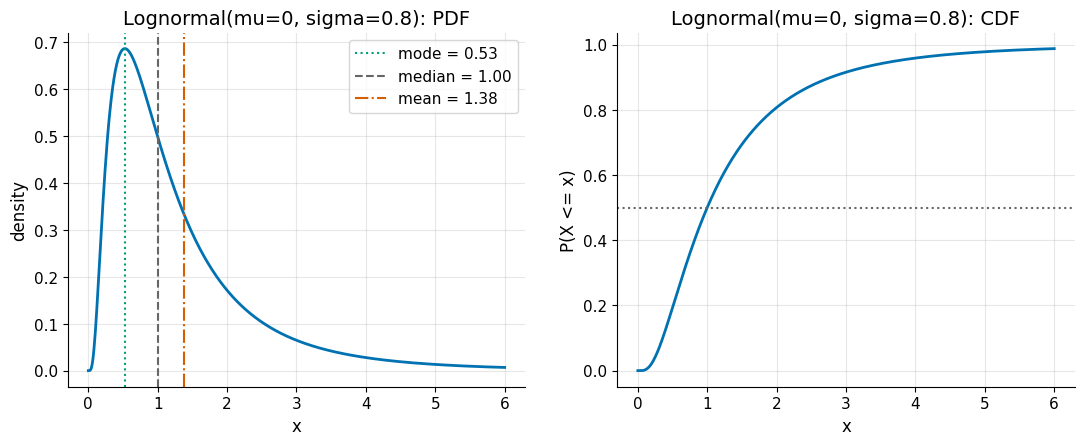

In [3]:
mu, sigma = 0.0, 0.8                                   # parameters of ln(X)
dist = stats.lognorm(s=sigma, scale=np.exp(mu))
x_axis = np.linspace(0.001, 6, 600)

mode_value = np.exp(mu - sigma**2)
median_value = np.exp(mu)
mean_value = np.exp(mu + sigma**2 / 2)

fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=(13, 4.6))
ax_pdf.plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2)
ax_pdf.axvline(mode_value, color=COLORS[2], linestyle=":", label=f"mode = {mode_value:.2f}")
ax_pdf.axvline(median_value, color=NEUTRAL, linestyle="--", label=f"median = {median_value:.2f}")
ax_pdf.axvline(mean_value, color=HIGHLIGHT, linestyle="-.", label=f"mean = {mean_value:.2f}")
ax_pdf.set_title("Lognormal(mu=0, sigma=0.8): PDF")
ax_pdf.set_xlabel("x")
ax_pdf.set_ylabel("density")
ax_pdf.legend()

ax_cdf.plot(x_axis, dist.cdf(x_axis), color=MAIN, linewidth=2)
ax_cdf.axhline(0.5, color=NEUTRAL, linestyle=":")
ax_cdf.set_title("Lognormal(mu=0, sigma=0.8): CDF")
ax_cdf.set_xlabel("x")
ax_cdf.set_ylabel("P(X <= x)")
plt.show()

### 7.2 Effect of sigma
With the median fixed at 1 (mu = 0), a larger sigma gives a taller right tail and moves the peak toward zero: the spread on the log scale becomes a huge spread on the original scale.

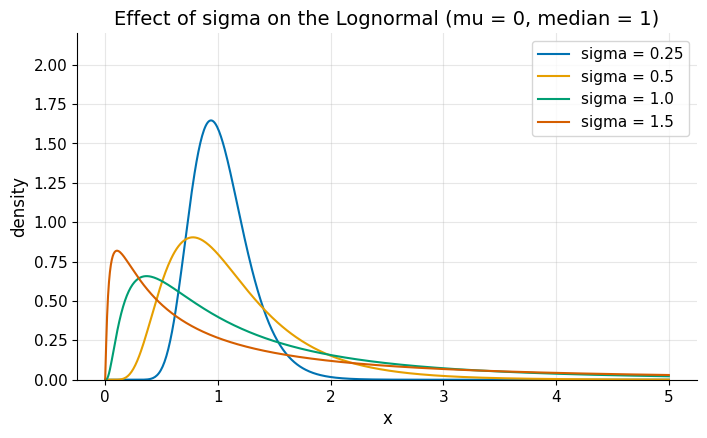

In [4]:
x_axis = np.linspace(0.001, 5, 600)
fig, ax = plt.subplots()
for sigma_value, color in zip([0.25, 0.5, 1.0, 1.5], COLORS):
    ax.plot(x_axis, stats.lognorm(s=sigma_value, scale=1).pdf(x_axis), color=color, label=f"sigma = {sigma_value}")
ax.set_title("Effect of sigma on the Lognormal (mu = 0, median = 1)")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_ylim(0, 2.2)
ax.legend()
plt.show()

### 7.3 Effect of mu
Changing mu multiplies every value by the same factor (the median is e^mu), so the curve is stretched horizontally, with the same shape on a log axis.

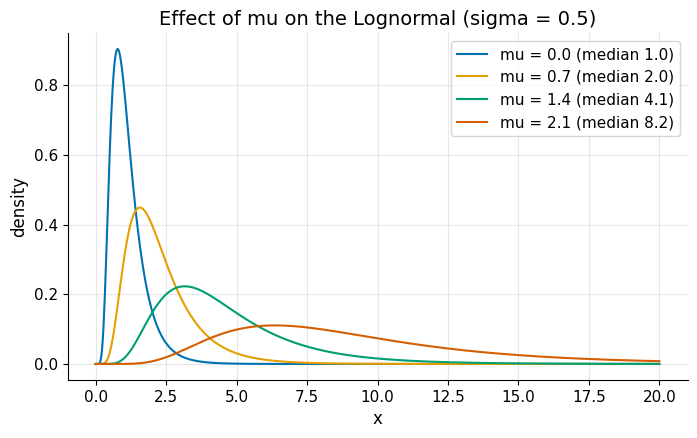

In [5]:
x_axis = np.linspace(0.001, 20, 800)
fig, ax = plt.subplots()
for mu_value, color in zip([0.0, 0.7, 1.4, 2.1], COLORS):
    ax.plot(x_axis, stats.lognorm(s=0.5, scale=np.exp(mu_value)).pdf(x_axis), color=color, label=f"mu = {mu_value} (median {np.exp(mu_value):.1f})")
ax.set_title("Effect of mu on the Lognormal (sigma = 0.5)")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 7.4 The log scale view
On a **logarithmic x axis** the same PDF looks like a bell, because ln X is Normal. This is the quickest visual test for lognormality: log-transform the data and look for a bell.

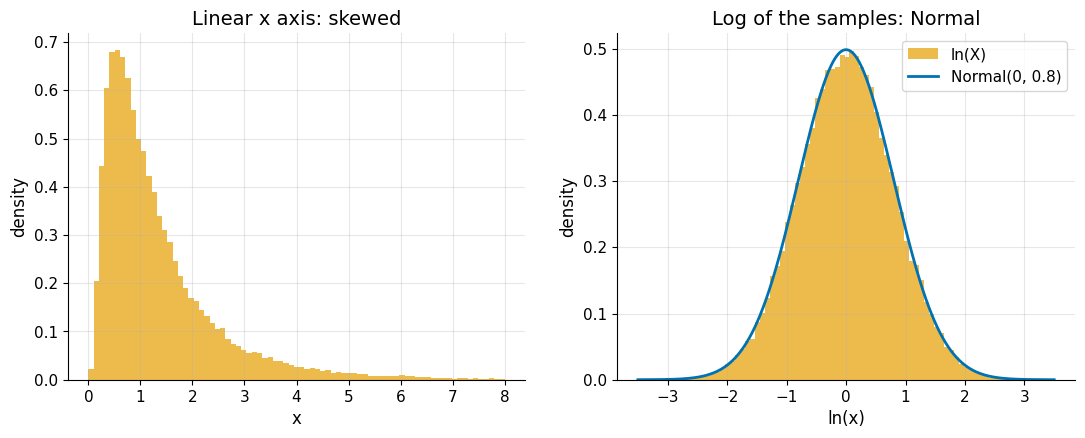

In [6]:
samples = dist.rvs(size=50_000, random_state=1)
fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_lin.hist(samples, bins=np.linspace(0, 8, 80), density=True, color=SIM, alpha=0.7)
ax_lin.set_title("Linear x axis: skewed")
ax_lin.set_xlabel("x")
ax_lin.set_ylabel("density")

ax_log.hist(np.log(samples), bins=80, density=True, color=SIM, alpha=0.7, label="ln(X)")
grid = np.linspace(-3.5, 3.5, 300)
ax_log.plot(grid, stats.norm(mu, sigma).pdf(grid), color=MAIN, linewidth=2, label="Normal(0, 0.8)")
ax_log.set_title("Log of the samples: Normal")
ax_log.set_xlabel("ln(x)")
ax_log.set_ylabel("density")
ax_log.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: PDF over (x, sigma), mu = 0
As sigma grows the ridge moves toward zero and grows a long tail along x.

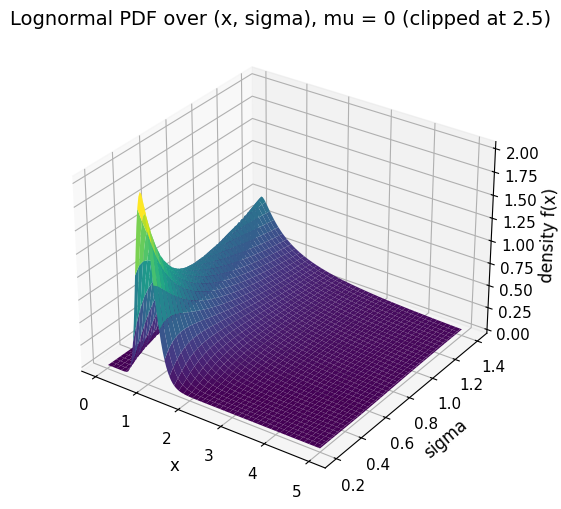

In [7]:
x_values = np.linspace(0.02, 5, 140)
sigma_values = np.linspace(0.2, 1.4, 40)
X, S = np.meshgrid(x_values, sigma_values)
Z = stats.lognorm.pdf(X, s=S, scale=1.0)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X, S, np.minimum(Z, 2.5), cmap="viridis", edgecolor="none")
ax.set_title("Lognormal PDF over (x, sigma), mu = 0 (clipped at 2.5)")
ax.set_xlabel("x")
ax.set_ylabel("sigma")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-55)
plt.show()

### 8.2 Static: PDF over (x, mu), sigma = 0.5
The ridge slides right and flattens as mu grows (a bigger median stretches the axis).

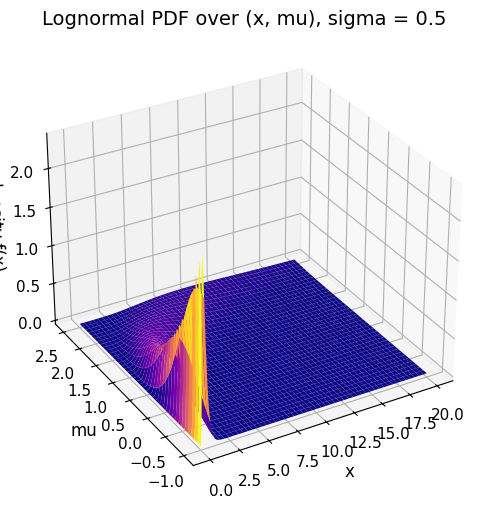

In [8]:
mu_values = np.linspace(-1, 2.5, 40)
x_values2 = np.linspace(0.02, 20, 200)
X2, M2 = np.meshgrid(x_values2, mu_values)
Z2 = stats.lognorm.pdf(X2, s=0.5, scale=np.exp(M2))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(X2, M2, Z2, cmap="plasma", edgecolor="none")
ax.set_title("Lognormal PDF over (x, mu), sigma = 0.5")
ax.set_xlabel("x")
ax.set_ylabel("mu")
ax.set_zlabel("density f(x)")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Interactive Plotly version
The (x, sigma) surface of 8.1; drag to rotate.

In [9]:
fig = go.Figure(go.Surface(x=x_values, y=sigma_values, z=np.minimum(Z, 2.5), colorscale="Viridis"))
fig.update_layout(title="Lognormal PDF over (x, sigma), mu = 0 (clipped at 2.5)", width=750, height=550,
                  scene=dict(xaxis_title="x", yaxis_title="sigma", zaxis_title="density f(x)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Histogram against the PDF
We draw 50,000 values with `rng.lognormal(mean, sigma)`. Careful: numpy's `mean` and `sigma` are mu and sigma of ln X, just like in our definition.

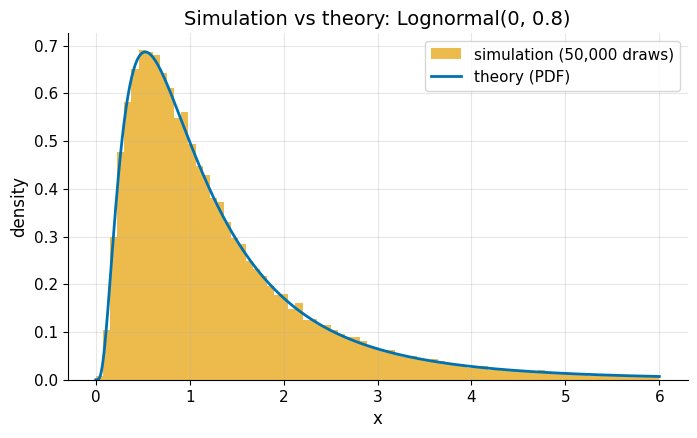

sample mean 1.386 vs theory 1.377; sample median 1.007 vs theory 1.000


In [10]:
samples = rng.lognormal(mean=mu, sigma=sigma, size=50_000)
x_axis = np.linspace(0.001, 6, 600)

fig, ax = plt.subplots()
ax.hist(samples, bins=np.linspace(0, 6, 80), density=True, color=SIM, alpha=0.7, label="simulation (50,000 draws)")
ax.plot(x_axis, dist.pdf(x_axis), color=MAIN, linewidth=2, label="theory (PDF)")
ax.set_title("Simulation vs theory: Lognormal(0, 0.8)")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()
print(f"sample mean {samples.mean():.3f} vs theory {mean_value:.3f}; sample median {np.median(samples):.3f} vs theory {median_value:.3f}")

### 9.2 The running mean converges slowly
The law of large numbers still applies, but a heavy right tail makes the running mean jumpy. Compare sigma = 0.3 (calm) with sigma = 1.5 (a few giant values dominate).

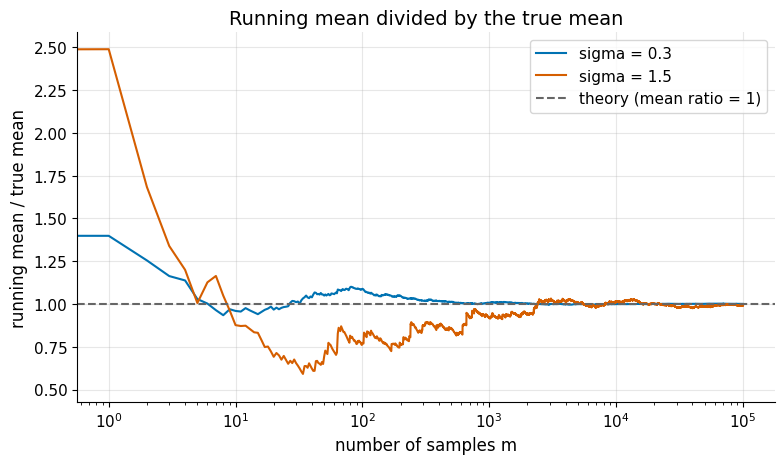

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.8))
for sigma_value, color in zip([0.3, 1.5], [COLORS[0], COLORS[3]]):
    draws = rng.lognormal(0, sigma_value, size=100_000)
    running_mean = np.cumsum(draws) / np.arange(1, len(draws) + 1)
    ax.plot(running_mean / np.exp(sigma_value**2 / 2), color=color, label=f"sigma = {sigma_value}")
ax.axhline(1, color=NEUTRAL, linestyle="--", label="theory (mean ratio = 1)")
ax.set_xscale("log")
ax.set_title("Running mean divided by the true mean")
ax.set_xlabel("number of samples m")
ax.set_ylabel("running mean / true mean")
ax.legend()
plt.show()

**In plain words.** The more skewed the data, the more samples you need before the average can be trusted. With sigma = 1.5 a handful of extreme values dominate for a long time.

## 10. `scipy.stats` cheat sheet

Remember: `lognorm(s=sigma, scale=exp(mu))`.

In [12]:
d = stats.lognorm(s=0.6, scale=120)        # median 120, sigma 0.6 on the log scale
print("pdf(120)        :", round(d.pdf(120), 6))
print("cdf(300)        P(X <= 300):", round(d.cdf(300), 5))
print("sf(300)         P(X > 300) :", round(d.sf(300), 5))
print("ppf(0.95)       95th pct   :", round(d.ppf(0.95), 2))
print("rvs(5)          draws      :", d.rvs(size=5, random_state=1).round(1))
print("mean, var       :", round(d.mean(), 2), round(d.var(), 1))
print("median          :", d.median())
print("interval(0.9)   :", np.round(d.interval(0.9), 1))
print("stats mvsk      :", np.round(d.stats(moments="mvsk"), 3))

pdf(120)        : 0.005541
cdf(300)        P(X <= 300): 0.93664
sf(300)         P(X > 300) : 0.06336
ppf(0.95)       95th pct   : 321.95
rvs(5)          draws      : [318.   83.1  87.4  63.  201.7]
mean, var       : 143.67 8943.9
median          : 120.0
interval(0.9)   : [ 44.7 322. ]
stats mvsk      : [1.436660e+02 8.943895e+03 2.260000e+00 1.027300e+01]


**Fitting:** fix the location at 0 with `floc=0` so only $s$ and `scale` are estimated. Then $\hat\sigma=$ `s` and $\hat\mu=\ln($`scale`$)$. These equal the mean and SD of $\ln x$.

In [13]:
data = rng.lognormal(mean=4.0, sigma=0.5, size=2000)
shape_hat, loc_hat, scale_hat = stats.lognorm.fit(data, floc=0)
print(f"fit: sigma = {shape_hat:.3f}, mu = {np.log(scale_hat):.3f}; direct: sigma = {np.log(data).std():.3f}, mu = {np.log(data).mean():.3f}")

fit: sigma = 0.504, mu = 4.010; direct: sigma = 0.504, mu = 4.010


## 11. Real-world worked examples

Three examples and a real-data fit. Example 1 has all five steps.

---
### Example 1 (main): API response latency

**Scenario (illustrative numbers).** The response time of a web API is Lognormal with a **median of 120 ms** and $\sigma=0.6$ on the log scale. So $\mu=\ln120=4.787$.

**Questions**
1. What is the **mean** latency, and why is it above the median?
2. What fraction of requests are **slower than 300 ms**?
3. What are the **95th and 99th percentiles** (typical service-level targets, SLOs)?

### 11.1 By hand
**Q1.** $E[X]=e^{\mu+\sigma^2/2}=120\times e^{0.6^2/2}=120\times e^{0.18}=120\times1.1972=143.7$ ms. The mean is 20 % above the median because a few very slow requests pull it up.

**Q2.** $z=\dfrac{\ln300-\mu}{\sigma}=\dfrac{5.7038-4.7875}{0.6}=1.527$. So $P(X>300)=1-\Phi(1.527)=1-0.9366=0.0634$.

**Q3.** The $p$-th percentile is $e^{\mu+z_p\sigma}$ with $z_{0.95}=1.6449$ and $z_{0.99}=2.3263$:
$x_{0.95}=120\,e^{1.6449\times0.6}=120\,e^{0.9869}=120\times2.683=322.0$ ms and $x_{0.99}=120\,e^{2.3263\times0.6}=120\,e^{1.3958}=120\times4.039=484.7$ ms (computed precisely in code).

In [14]:
import math

median_latency = 120
sigma_log = 0.6
mu_log = math.log(median_latency)

def standard_normal_cdf(z):
    return 0.5 * (1 + math.erf(z / math.sqrt(2)))

mean_hand = math.exp(mu_log + sigma_log**2 / 2)
z_300 = (math.log(300) - mu_log) / sigma_log
p_slower_300_hand = 1 - standard_normal_cdf(z_300)
p95_hand = math.exp(mu_log + 1.6449 * sigma_log)       # z values taken from the table
p99_hand = math.exp(mu_log + 2.3263 * sigma_log)
print(f"mean = {mean_hand:.1f} ms, P(X > 300) = {p_slower_300_hand:.4f}, p95 = {p95_hand:.1f} ms, p99 = {p99_hand:.1f} ms")

mean = 143.7 ms, P(X > 300) = 0.0634, p95 = 322.0 ms, p99 = 484.6 ms


### 11.2 In code with `scipy`, and the asserts

In [15]:
latency = stats.lognorm(s=sigma_log, scale=median_latency)

mean_code = latency.mean()
p_slower_300_code = latency.sf(300)
p95_code = latency.ppf(0.95)
p99_code = latency.ppf(0.99)

assert np.isclose(mean_hand, mean_code)
assert np.isclose(p_slower_300_hand, p_slower_300_code)
assert np.isclose(p95_hand, p95_code, rtol=1e-3)
assert np.isclose(p99_hand, p99_code, rtol=1e-3)
print(f"mean = {mean_code:.1f} ms, median = {latency.median():.1f} ms, SD = {latency.std():.1f} ms")
print(f"P(X > 300 ms) = {p_slower_300_code:.4f}")
print(f"p95 = {p95_code:.1f} ms, p99 = {p99_code:.1f} ms")

mean = 143.7 ms, median = 120.0 ms, SD = 94.6 ms
P(X > 300 ms) = 0.0634
p95 = 322.0 ms, p99 = 484.6 ms


### 11.3 Verify by simulation

In [16]:
simulated = rng.lognormal(mean=mu_log, sigma=sigma_log, size=500_000)
print(f"mean:       exact {mean_code:.1f}  simulated {simulated.mean():.1f}")
print(f"P(X > 300): exact {p_slower_300_code:.4f}  simulated {np.mean(simulated > 300):.4f}")
print(f"p95:        exact {p95_code:.1f}  simulated {np.percentile(simulated, 95):.1f}")
print(f"p99:        exact {p99_code:.1f}  simulated {np.percentile(simulated, 99):.1f}")
assert abs(np.mean(simulated > 300) - p_slower_300_code) < 0.002
assert abs(np.percentile(simulated, 99) / p99_code - 1) < 0.02

mean:       exact 143.7  simulated 143.7
P(X > 300): exact 0.0634  simulated 0.0635
p95:        exact 322.0  simulated 321.9
p99:        exact 484.6  simulated 486.2


### 11.4 Plots with the regions shaded

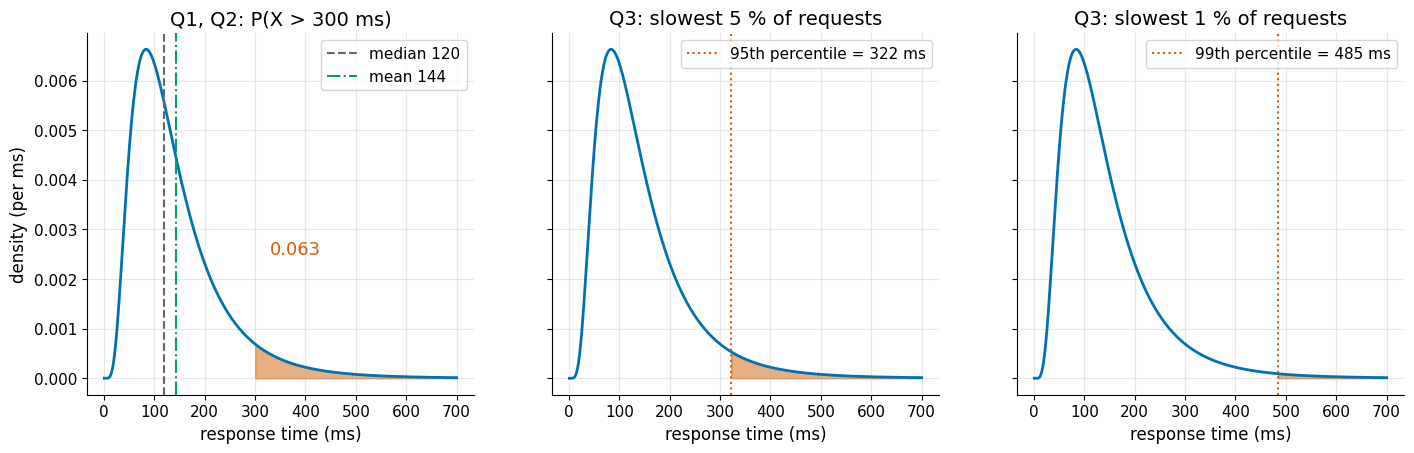

In [17]:
x_axis = np.linspace(1, 700, 800)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.7), sharey=True)

tail = x_axis > 300
axes[0].plot(x_axis, latency.pdf(x_axis), color=MAIN, linewidth=2)
axes[0].fill_between(x_axis[tail], latency.pdf(x_axis[tail]), color=HIGHLIGHT, alpha=0.5)
axes[0].axvline(latency.median(), color=NEUTRAL, linestyle="--", label="median 120")
axes[0].axvline(mean_code, color=COLORS[2], linestyle="-.", label=f"mean {mean_code:.0f}")
axes[0].set_title("Q1, Q2: P(X > 300 ms)")
axes[0].text(330, 0.0025, f"{p_slower_300_code:.3f}", color=HIGHLIGHT, fontsize=13)
axes[0].set_xlabel("response time (ms)")
axes[0].set_ylabel("density (per ms)")
axes[0].legend()

for ax, quantile, value in [(axes[1], 0.95, p95_code), (axes[2], 0.99, p99_code)]:
    beyond = x_axis >= value
    ax.plot(x_axis, latency.pdf(x_axis), color=MAIN, linewidth=2)
    ax.fill_between(x_axis[beyond], latency.pdf(x_axis[beyond]), color=HIGHLIGHT, alpha=0.5)
    ax.axvline(value, color=HIGHLIGHT, linestyle=":", label=f"{int(quantile * 100)}th percentile = {value:.0f} ms")
    ax.set_title(f"Q3: slowest {int((1 - quantile) * 100)} % of requests")
    ax.set_xlabel("response time (ms)")
    ax.legend()
plt.show()

### 11.5 Interpretation and decision
- The **typical request takes 120 ms (median), but the average is 144 ms.** If you quote the mean to users, it overstates what a typical request feels like and understates the slow cases.
- About **6 % of requests exceed 300 ms**, roughly 1 in 16.
- The **95th percentile is 322 ms** and the **99th is 485 ms**: four times the median.
- **Decision:** write the SLO on percentiles, for example "95 % of requests under 350 ms and 99 % under 500 ms". Monitor p99, not the mean, since a few slow requests dominate user complaints.

---
### Example 2: household income

**Scenario (illustrative).** Annual household income in a region is Lognormal with a **median of 50,000** and $\sigma=0.8$.

**Questions:** (a) the mean income and the ratio mean/median; (b) the share of households earning more than 100,000; (c) the income threshold of the top 10 %.

**By hand.** (a) mean $=50{,}000\,e^{0.32}=50{,}000\times1.377=68{,}856$, ratio $e^{\sigma^2/2}=1.377$. (b) $z=\frac{\ln100000-\ln50000}{0.8}=\frac{\ln2}{0.8}=0.866$, so $P=1-\Phi(0.866)=0.1932$. (c) $x_{0.90}=50{,}000\,e^{1.2816\times0.8}=50{,}000\times2.788=139{,}400$.

In [18]:
median_income, sigma_income = 50_000, 0.8
income = stats.lognorm(s=sigma_income, scale=median_income)

mean_income_hand = median_income * math.exp(sigma_income**2 / 2)
share_over_100k_hand = 1 - standard_normal_cdf(math.log(2) / sigma_income)
top10_hand = median_income * math.exp(1.2816 * sigma_income)

assert np.isclose(mean_income_hand, income.mean())
assert np.isclose(share_over_100k_hand, income.sf(100_000))
assert np.isclose(top10_hand, income.ppf(0.90), rtol=1e-3)
print(f"mean = {income.mean():,.0f}, median = {income.median():,.0f}; share above 100k = {income.sf(100_000):.3f}; top 10% from {income.ppf(0.90):,.0f}")

simulated_income = rng.lognormal(math.log(median_income), sigma_income, size=300_000)
print(f"simulated share above 100k = {np.mean(simulated_income > 100_000):.3f}; share of households earning less than the mean = {np.mean(simulated_income < income.mean()):.3f}")

mean = 68,856, median = 50,000; share above 100k = 0.193; top 10% from 139,388
simulated share above 100k = 0.194; share of households earning less than the mean = 0.655


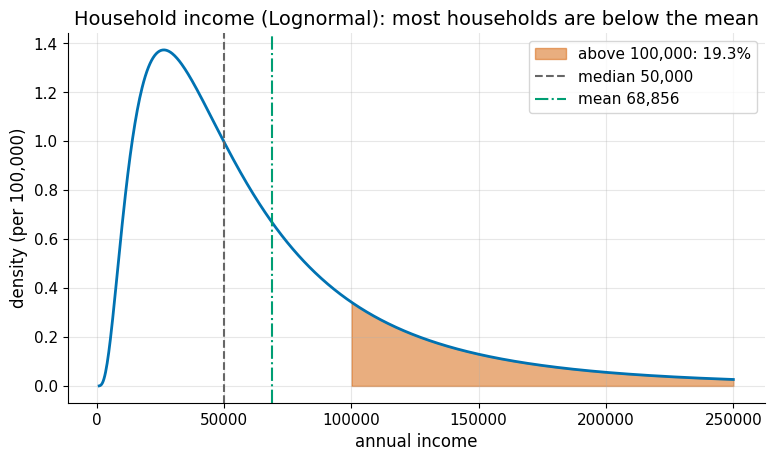

In [19]:
x_axis = np.linspace(1000, 250_000, 800)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, income.pdf(x_axis) * 1e5, color=MAIN, linewidth=2)
tail = x_axis > 100_000
ax.fill_between(x_axis[tail], income.pdf(x_axis[tail]) * 1e5, color=HIGHLIGHT, alpha=0.5, label=f"above 100,000: {income.sf(100_000):.1%}")
ax.axvline(income.median(), color=NEUTRAL, linestyle="--", label="median 50,000")
ax.axvline(income.mean(), color=COLORS[2], linestyle="-.", label=f"mean {income.mean():,.0f}")
ax.set_title("Household income (Lognormal): most households are below the mean")
ax.set_xlabel("annual income")
ax.set_ylabel("density (per 100,000)")
ax.legend()
plt.show()

**Interpretation.** About **65 % of households earn less than the average**, because the mean is pulled up by high earners. Report the median to describe a typical household. One household in five earns more than twice the median, and the top 10 % start near 139,000. A policy based on "the average income" would miss most families.

---
### Example 3: investment growth (the multiplicative CLT)

**Scenario (illustrative).** A fund's yearly growth factor is Lognormal with $\mu=0.05$ and $\sigma=0.20$ for the log return. You invest 10,000 for 1 year.

**Questions:** (a) the median and mean final value; (b) the probability of ending below 10,000 (a loss); (c) the 5th percentile (a bad-year value).

**By hand.** Final value $V=10{,}000\,e^{Y}$ with $Y\sim N(0.05,0.2^2)$, so $V$ is Lognormal with median $10{,}000e^{0.05}=10{,}513$ and mean $10{,}513\,e^{0.02}=10{,}725$. Loss means $Y<0$: $P=\Phi\big(\frac{0-0.05}{0.2}\big)=\Phi(-0.25)=0.4013$. The 5th percentile is $10{,}000\,e^{0.05-1.6449\times0.2}=10{,}000\,e^{-0.2790}=7{,}566$.

In [20]:
investment = stats.lognorm(s=0.20, scale=10_000 * math.exp(0.05))

median_hand = 10_000 * math.exp(0.05)
mean_hand_inv = median_hand * math.exp(0.20**2 / 2)
p_loss_hand = standard_normal_cdf((0 - 0.05) / 0.20)
p5_hand = 10_000 * math.exp(0.05 - 1.6449 * 0.20)

assert np.isclose(mean_hand_inv, investment.mean())
assert np.isclose(p_loss_hand, investment.cdf(10_000))
assert np.isclose(p5_hand, investment.ppf(0.05), rtol=1e-3)
print(f"median {investment.median():,.0f}, mean {investment.mean():,.0f}, P(loss) = {investment.cdf(10_000):.4f}, 5th percentile {investment.ppf(0.05):,.0f}")

# Over 20 years the growth multiplies: the product of 20 independent factors is again Lognormal.
twenty_year = stats.lognorm(s=0.20 * math.sqrt(20), scale=10_000 * math.exp(0.05 * 20))
print(f"after 20 years: median {twenty_year.median():,.0f}, mean {twenty_year.mean():,.0f}, 5th percentile {twenty_year.ppf(0.05):,.0f}, P(end below 10,000) = {twenty_year.cdf(10_000):.3f}")
simulated_final = 10_000 * np.exp(rng.normal(0.05, 0.20, size=(100_000, 20)).sum(axis=1))
print(f"simulated 20-year median {np.median(simulated_final):,.0f} (theory {twenty_year.median():,.0f})")
assert abs(np.median(simulated_final) / twenty_year.median() - 1) < 0.02

median 10,513, mean 10,725, P(loss) = 0.4013, 5th percentile 7,566
after 20 years: median 27,183, mean 40,552, 5th percentile 6,243, P(end below 10,000) = 0.132
simulated 20-year median 27,194 (theory 27,183)


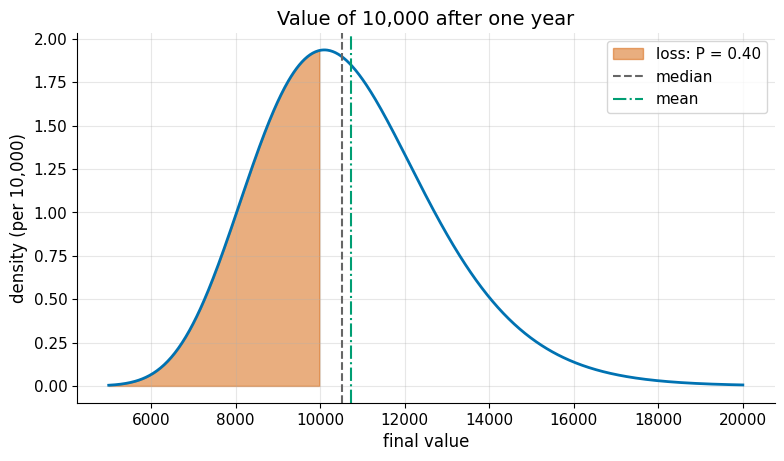

In [21]:
x_axis = np.linspace(5_000, 20_000, 700)
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(x_axis, investment.pdf(x_axis) * 1e4, color=MAIN, linewidth=2)
loss = x_axis < 10_000
ax.fill_between(x_axis[loss], investment.pdf(x_axis[loss]) * 1e4, color=HIGHLIGHT, alpha=0.5, label=f"loss: P = {investment.cdf(10_000):.2f}")
ax.axvline(investment.median(), color=NEUTRAL, linestyle="--", label="median")
ax.axvline(investment.mean(), color=COLORS[2], linestyle="-.", label="mean")
ax.set_title("Value of 10,000 after one year")
ax.set_xlabel("final value")
ax.set_ylabel("density (per 10,000)")
ax.legend()
plt.show()

**Interpretation.** A one-year investment has a **40 % chance of losing money** even though the expected return is positive: the fund gains 5 % on the log scale but with 20 % spread. Over 20 years the median grows to about 27,000 and the chance of ending below the starting 10,000 falls to about **13 %**, so **time reduces the chance of loss** when the median growth is positive. But the spread explodes: the 5th percentile is only about 6,200 while the mean (about 40,600) is far above the median. The median path is the one to plan for, not the mean.

---
### Real data: restaurant bills, Normal or Lognormal?
In 02_01 the `total_bill` of the `tips` dataset (244 parties) failed the normality check: it is positive and right-skewed. We now fit both a Normal and a Lognormal and compare them in four ways: histogram, **Q-Q plot of ln(bill)**, log-likelihood (higher is better) and the **AIC** (lower is better; it penalizes the number of parameters).

In [22]:
import pathlib
tips_path = pathlib.Path("../data/tips.csv")
if not tips_path.exists():
    raise FileNotFoundError("Run `python ../data/download_data.py` first to download the dataset.")
bills = pd.read_csv(tips_path)["total_bill"].to_numpy()

mu_normal, sigma_normal = stats.norm.fit(bills)
shape_ln, loc_ln, scale_ln = stats.lognorm.fit(bills, floc=0)
normal_fit = stats.norm(mu_normal, sigma_normal)
lognormal_fit = stats.lognorm(s=shape_ln, scale=scale_ln)
print(f"Normal fit:    mu = {mu_normal:.2f}, sigma = {sigma_normal:.2f}")
print(f"Lognormal fit: mu (log) = {np.log(scale_ln):.3f}, sigma (log) = {shape_ln:.3f}; implied median = {scale_ln:.2f}, mean = {lognormal_fit.mean():.2f}")

Normal fit:    mu = 19.79, sigma = 8.88
Lognormal fit: mu (log) = 2.890, sigma (log) = 0.438; implied median = 18.00, mean = 19.81


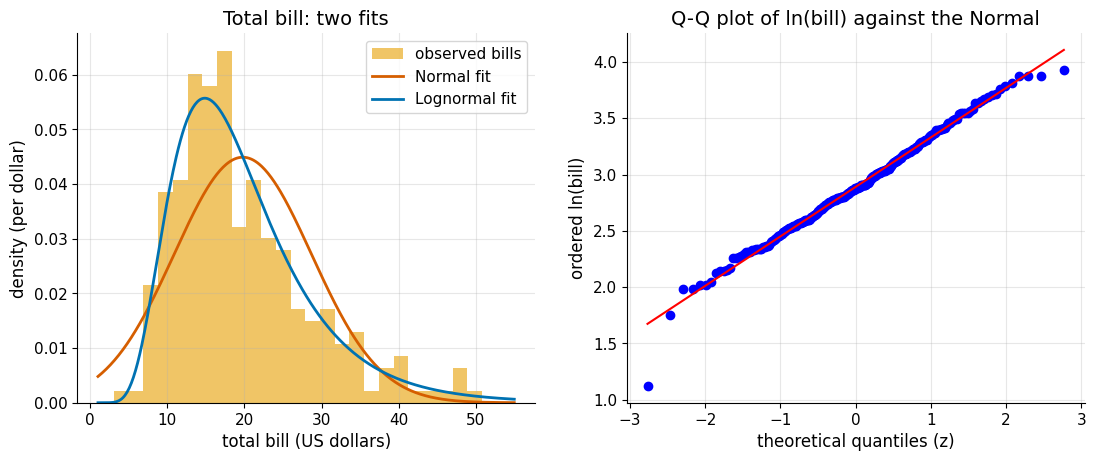

log-likelihood: Normal -879.2, Lognormal -850.0
AIC:            Normal 1762.4, Lognormal 1704.0  (lower is better)


In [23]:
fig, (ax_hist, ax_qq) = plt.subplots(1, 2, figsize=(13, 4.8))
grid = np.linspace(1, 55, 400)
ax_hist.hist(bills, bins=25, density=True, color=SIM, alpha=0.6, label="observed bills")
ax_hist.plot(grid, normal_fit.pdf(grid), color=HIGHLIGHT, linewidth=2, label="Normal fit")
ax_hist.plot(grid, lognormal_fit.pdf(grid), color=MAIN, linewidth=2, label="Lognormal fit")
ax_hist.set_title("Total bill: two fits")
ax_hist.set_xlabel("total bill (US dollars)")
ax_hist.set_ylabel("density (per dollar)")
ax_hist.legend()

stats.probplot(np.log(bills), dist="norm", plot=ax_qq)
ax_qq.set_title("Q-Q plot of ln(bill) against the Normal")
ax_qq.set_xlabel("theoretical quantiles (z)")
ax_qq.set_ylabel("ordered ln(bill)")
plt.show()

loglik_normal = normal_fit.logpdf(bills).sum()
loglik_lognormal = lognormal_fit.logpdf(bills).sum()
aic_normal = 2 * 2 - 2 * loglik_normal               # AIC = 2 * (number of parameters) - 2 * log-likelihood
aic_lognormal = 2 * 2 - 2 * loglik_lognormal
print(f"log-likelihood: Normal {loglik_normal:.1f}, Lognormal {loglik_lognormal:.1f}")
print(f"AIC:            Normal {aic_normal:.1f}, Lognormal {aic_lognormal:.1f}  (lower is better)")
assert loglik_lognormal > loglik_normal

**Reading the result.** The Lognormal follows the skewed shape much better (higher log-likelihood and lower AIC with the same number of parameters), and the Q-Q plot of ln(bill) is much closer to a straight line than the raw Q-Q plot in 02_01. Practical use: the implied **median bill is about 18 dollars** and the mean about 20: the typical party spends less than the average. The Lognormal is still only a model: check the ends of the Q-Q plot, and judge the fit by how it will be used.

## 12. Where it is used

### Statistics
- **Multiplicative errors and positive data:** analyzing ln(y) instead of y (log-linear regression) turns the model additive, and the exponentiated coefficients are interpreted as percentage effects.
- **Geometric mean and geometric SD** summarize skewed positive data, as in lab measurements and pharmacokinetics.
- **Confidence intervals for ratios** (such as relative risk) are built on the log scale.

### Data science
- **Response times, file sizes, order values, incomes, house prices:** all typically lognormal-like; use log transforms before modelling, and report medians and percentiles.
- **Capacity and SLO planning** from percentiles (Example 1).

### ML and AI
- **Log-transform of skewed targets** (prices, durations) stabilizes training and corresponds to a Lognormal error model.
- **Learning-rate and hyperparameter search** is usually done on a log scale (a log-uniform prior).
- **Multiplicative noise** and token/document length modelling often use Lognormal.

## 13. Common pitfalls and misconceptions

- **mu and sigma are parameters of ln X, not of X.** The mean of X is not mu, and the SD of X is not sigma.
- **`scipy` uses `scale = exp(mu)`** and the shape `s = sigma`. Passing mu as `scale` is the classic bug.
- **Mean vs median:** for skewed data, quoting only the mean misleads. The median is `exp(mu)`.
- **log(0) and negative values:** Lognormal needs strictly positive data; take care with zeros before logging (`log1p` helps).
- **Looks like a power law:** a straight stretch on a log-log plot does not prove a Pareto; the Lognormal also looks straight over a wide range.
- **Sample mean of lognormal data converges slowly** when sigma is large (section 9.2).
- **Averaging log returns vs averaging returns:** the median growth uses the mean of the logs; the arithmetic mean of the factors is larger.

## 14. Exercises

1. If $\ln X\sim N(2,0.5^2)$, find the median, mean and mode of $X$.
2. Package delivery times are Lognormal with median 3 days and $\sigma=0.4$. What fraction takes more than 5 days? What is the 90th percentile?
3. Show that if $X\sim LN(\mu,\sigma^2)$, then $1/X\sim LN(-\mu,\sigma^2)$ and $X^2\sim LN(2\mu,4\sigma^2)$.
4. Two independent lognormal variables $X_1\sim LN(1,0.3^2)$ and $X_2\sim LN(0.5,0.4^2)$: what is the distribution of $X_1X_2$, and what is its median?
5. Using code, find the value of $\sigma$ for which the mean is exactly twice the median.
6. A dataset has sample mean 50 and sample median 30. If it is Lognormal, estimate $\mu$ and $\sigma$.
7. (Harder) Derive the mode $e^{\mu-\sigma^2}$ of the Lognormal by maximizing $\ln f$.
8. (Harder) Simulate the product of 100 independent Uniform(0.9, 1.15) factors 50,000 times and test whether the log of the product is Normal (Q-Q plot or Shapiro-Wilk on a subsample).

Solutions are at the end.

## 15. Summary table

| Item | Value |
|---|---|
| Parameters | mu (mean of ln X), sigma > 0 (SD of ln X) |
| Support | x > 0 |
| PDF | 1 / (x sigma sqrt(2 pi)) exp(-(ln x - mu)^2 / (2 sigma^2)) |
| Median | exp(mu) |
| Mean | exp(mu + sigma^2/2) |
| Variance | (exp(sigma^2) - 1) exp(2 mu + sigma^2) |
| Mode | exp(mu - sigma^2) |
| Skewness | (exp(sigma^2) + 2) sqrt(exp(sigma^2) - 1) |
| When to use | positive, right-skewed quantities made by multiplication (incomes, latencies, sizes) |
| `scipy` name | `stats.lognorm(s=sigma, scale=np.exp(mu))` |

## Solutions

In [24]:
mu_ex, sigma_ex = 2, 0.5
print("1: median", round(np.exp(mu_ex), 3), "mean", round(np.exp(mu_ex + sigma_ex**2 / 2), 3), "mode", round(np.exp(mu_ex - sigma_ex**2), 3))
delivery = stats.lognorm(s=0.4, scale=3)
print("2: P(>5 days) =", round(delivery.sf(5), 4), " 90th percentile =", round(delivery.ppf(0.9), 3))
product = stats.lognorm(s=np.sqrt(0.3**2 + 0.4**2), scale=np.exp(1 + 0.5))
print("4: X1 X2 ~ LN(1.5, 0.5^2); median =", round(product.median(), 3))
from scipy import optimize
sigma_double = optimize.brentq(lambda s: np.exp(s**2 / 2) - 2, 0.01, 3)
print("5: sigma =", round(sigma_double, 4), "(= sqrt(2 ln 2) =", round(np.sqrt(2 * np.log(2)), 4), ")")
mu6 = np.log(30)
sigma6 = np.sqrt(2 * (np.log(50) - mu6))
print("6: mu =", round(mu6, 3), " sigma =", round(sigma6, 3))
prods = np.log(rng.uniform(0.9, 1.15, size=(50_000, 100))).sum(axis=1)
print("8: Shapiro p-value on 2000 log-products:", round(stats.shapiro(prods[:2000]).pvalue, 3), " skewness of the log:", round(stats.skew(prods), 3))

1: median 7.389 mean 8.373 mode 5.755
2: P(>5 days) = 0.1008  90th percentile = 5.009
4: X1 X2 ~ LN(1.5, 0.5^2); median = 4.482
5: sigma = 1.1774 (= sqrt(2 ln 2) = 1.1774 )
6: mu = 3.401  sigma = 1.011


8: Shapiro p-value on 2000 log-products: 0.023  skewness of the log: -0.004


**1.** Median $e^2=7.389$, mean $e^{2+0.125}=8.372$, mode $e^{2-0.25}=5.755$.

**2.** $z=(\ln5-\ln3)/0.4=1.277$, so about 10 % take more than 5 days (printed above); the 90th percentile is $3e^{1.2816\times0.4}\approx5.0$ days.

**3.** $\ln(1/X)=-Y\sim N(-\mu,\sigma^2)$ and $\ln(X^2)=2Y\sim N(2\mu,4\sigma^2)$.

**4.** $\ln(X_1X_2)\sim N(1.5,0.3^2+0.4^2=0.25)$, so $X_1X_2\sim LN(1.5,0.5^2)$ with median $e^{1.5}=4.48$.

**5.** Mean/median $=e^{\sigma^2/2}=2\Rightarrow\sigma=\sqrt{2\ln2}=1.177$.

**6.** Median 30 gives $\mu=\ln30=3.40$. Mean/median $=e^{\sigma^2/2}=50/30\Rightarrow\sigma^2=2\ln(5/3)=1.022$, $\sigma\approx1.01$.

**7.** $\ln f=-\ln x-\frac{(\ln x-\mu)^2}{2\sigma^2}+c$; derivative $-\frac1x-\frac{\ln x-\mu}{\sigma^2x}=0\Rightarrow\ln x=\mu-\sigma^2$.

**8.** The log of the product is a sum of 100 independent terms, so it is essentially Normal: its skewness is about 0 and the Q-Q plot is a straight line. (With thousands of points Shapiro-Wilk can still flag tiny deviations, so do not rely on its p-value alone.)